<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/statistics/monteCarloSampling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Samples generated: 100,000
Mean     -> Monte Carlo: 0.40056 | Theoretical: 0.40000
Variance -> Monte Carlo: 0.16008 | Theoretical: 0.16000


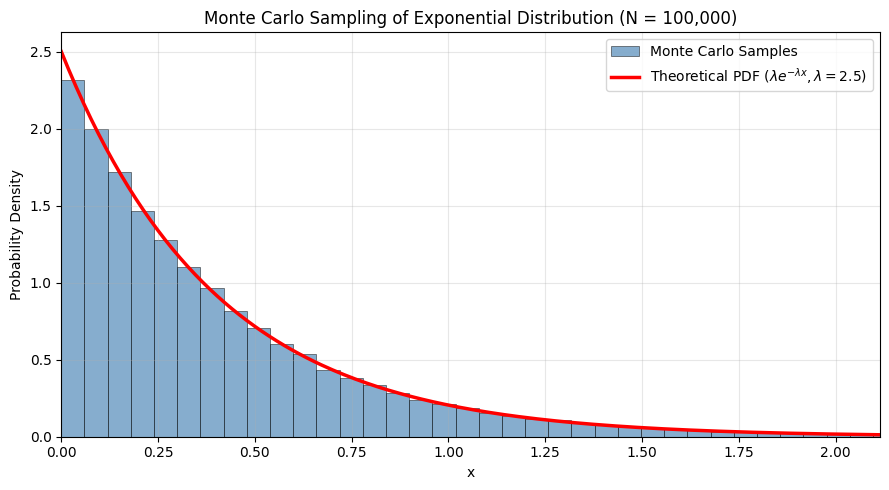

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sample_exponential_mc(lam: float, num_samples: int, seed: int = 42) -> np.ndarray:
    """
    Samples from an Exponential(lambda) distribution using Monte Carlo
    inverse transform sampling.

    Parameters:
    lam (float): Rate parameter (lambda > 0). Scale = 1 / lambda.
    num_samples (int): Number of Monte Carlo samples to generate.
    seed (int): Random seed for reproducibility.
    """
    if lam <= 0:
        raise ValueError("Rate parameter 'lam' must be strictly positive.")

    rng = np.random.default_rng(seed)

    # 1. Generate uniform random numbers U in (0, 1)
    # Note: rng.random() generates values in [0.0, 1.0). Using 1.0 - U avoids log(0).
    u = rng.random(num_samples)

    # 2. Apply the inverse CDF: F^-1(u) = -ln(1 - u) / lambda
    samples = -np.log(1.0 - u) / lam

    return samples

# --- Parameters ---
lam = 2.5              # Rate parameter (mean = 1/2.5 = 0.4)
num_samples = 100_000  # Number of Monte Carlo draws

# Generate samples
mc_samples = sample_exponential_mc(lam, num_samples)

# --- Verification: Compare Empirical vs. Theoretical Moments ---
theoretical_mean = 1.0 / lam
theoretical_var = 1.0 / (lam ** 2)

print(f"Samples generated: {num_samples:,}")
print(f"Mean     -> Monte Carlo: {np.mean(mc_samples):.5f} | Theoretical: {theoretical_mean:.5f}")
print(f"Variance -> Monte Carlo: {np.var(mc_samples):.5f} | Theoretical: {theoretical_var:.5f}")

# --- Plotting ---
plt.figure(figsize=(9, 5))

# Plot normalized histogram of Monte Carlo samples
plt.hist(mc_samples, bins=80, density=True, alpha=0.65, color='steelblue',
         edgecolor='black', linewidth=0.5, label='Monte Carlo Samples')

# Plot exact theoretical PDF: f(x) = lambda * exp(-lambda * x)
x_vals = np.linspace(0, np.max(mc_samples), 500)
pdf_vals = lam * np.exp(-lam * x_vals)
plt.plot(x_vals, pdf_vals, 'r-', lw=2.5, label=rf'Theoretical PDF ($\lambda e^{{-\lambda x}}, \lambda={lam}$)')

plt.title(f"Monte Carlo Sampling of Exponential Distribution (N = {num_samples:,})")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.xlim(0, np.percentile(mc_samples, 99.5))  # Zoom in on main distribution body
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()